In [12]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import numpy as np

data = load_iris(as_frame = True)
df = data.frame
dic = {x:y for x,y in zip(range(3), data.target_names)}
df['target'] = df['target'].map(dic)


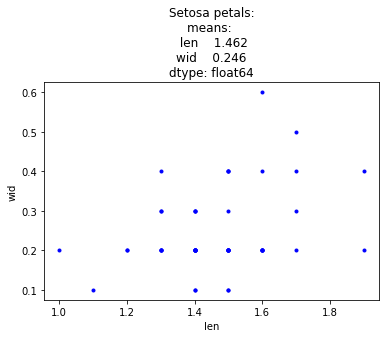

In [13]:
# Setosa petals
df_sp = df.query('target == "setosa"').filter(regex = 'petal').rename(columns = {'petal length (cm)':'len', 'petal width (cm)':'wid'})
plt.plot(df_sp.set_index('len'), ' .b')
plt.ylabel('wid')
plt.xlabel('len')
plt.title(f'Setosa petals:\nmeans: \n {df_sp.mean()}')
df_sp.shape, df_sp.head()
plt.show()

,len,wid
0,-0.357011,-0.436492
1,-0.357011,-0.436492
2,-0.932836,-0.436492
3,0.218813,-0.436492
4,-0.357011,-0.436492


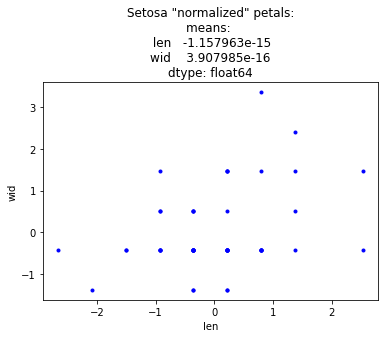

In [14]:
# normalized values for mean and std
df_spn = (
    df_sp.copy()
    .assign(len = lambda x:( x['len'] - x['len'].mean())/x['len'].std())
    .assign(wid = lambda x:( x['wid'] - x['wid'].mean())/x['wid'].std())
)
display(df_spn.head())
plt.plot(df_spn.set_index('len'), ' .b')
plt.ylabel('wid')
plt.xlabel('len')
plt.title(f'Setosa "normalized" petals:\nmeans: \n {df_spn.mean()}')
plt.show()

In [15]:
# relationship between len and wid:

# deviation: value minus mean
dl = df_sp['len'].values - df_sp['len'].mean() # deviation for length
dw = df_sp['wid'].values - df_sp['wid'].mean()

# variance: squared mean of deviation
var_l = np.mean(dl**2)
var_w = np.mean(dw**2)

# standard deviation: root square of variance
std_l = np.sqrt(np.mean(dl**2))
std_w = np.sqrt(np.mean(dw**2))
std_l, var_l

# covariance: mean of product of deviations
cov = np.mean(dl * dw)

# pearson: covariance divided by product of both standard deviations
pearson_corr = cov/(std_l*std_w)

In [16]:
# validation
print('validation!')
print(f'variance for len: numpy = {np.var(df_sp["len"], ddof = 0)}; manual = {var_l}')
print(f'std for len: numpy = {np.std(df_sp["len"], ddof = 0)}; manual = {std_l}')
print('\n')
print(f'variance for wid: numpy = {np.var(df_sp["wid"], ddof = 0)}; manual = {var_w}')
print(f'std for wid: numpy = {np.std(df_sp["wid"], ddof = 0)}; manual = {std_w}')
print('\n')
print(f'covariance: numpy = {np.cov(dl, dw, ddof = 0)[0,1]}, manual = {cov}')
print(f'pearson correlation: numpy = {np.corrcoef(dl, dw)[0,1]}, manual = {pearson_corr}')

validation!
variance for len: numpy = 0.029555999999999995; manual = 0.029555999999999995
std for len: numpy = 0.17191858538273283; manual = 0.17191858538273283


variance for wid: numpy = 0.010883999999999998; manual = 0.010883999999999998
std for wid: numpy = 0.1043264108459598; manual = 0.1043264108459598


covariance: numpy = 0.005948000000000001, manual = 0.005948000000000001
pearson correlation: numpy = 0.3316300408041188, manual = 0.3316300408041188


#### linear regression:
```python
a = covariance/variance of x_axis # cov/var_l
x = x_axis # array, df_sp['len']
b = mean(y_axis) - a*mean(x_axis) # np.mean(df_sp['wid']) - (cov/var_l) * np.mean(df_sp['len'])

# y = prediction

y = a*x + b


```

In [17]:
# prediction time!
a1_xl = cov/var_l
a0_xl = np.mean(df_sp['wid']) - (cov/var_l) * np.mean(df_sp['len'])

a1_xw = cov/var_w

cov/(var_l), cov/(var_w)

(0.20124509405873603, 0.5464902609334805)

In [18]:
# validation:
print(f'if x/independent variable is len: numpy = {np.polyfit(x = df_sp["len"], y = df_sp["wid"], deg = 1)}, manual = {a1_xl, a0_xl}')
print(f'if x/independent variable is wid: numpy = {np.polyfit(y = df_sp["len"], x = df_sp["wid"], deg = 1)[0]}, manual = {a1_xw}')

if x/independent variable is len: numpy = [ 0.20124509 -0.04822033], manual = (0.20124509405873603, -0.04822032751387215)
if x/independent variable is wid: numpy = 0.5464902609334812, manual = 0.5464902609334805


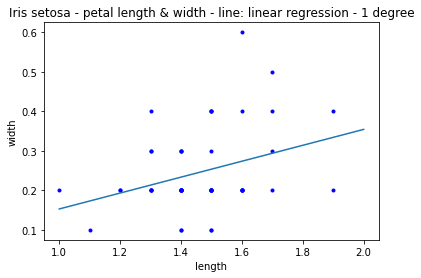

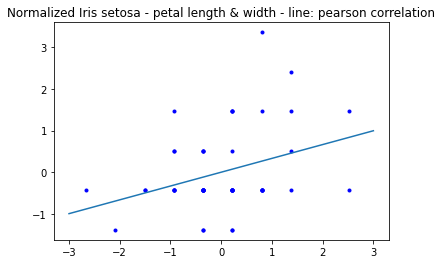

In [19]:
# sth cool: the normalized data with pvalue instead of slope is very similar to the real data with regression!
plt.plot(df_sp.set_index('len'), ' .b')
plt.plot([1,2],[1*a1_xl + a0_xl, 2*a1_xl + a0_xl])
plt.ylabel('width')
plt.xlabel('length')
plt.title('Iris setosa - petal length & width - line: linear regression - 1 degree')
plt.show()
plt.plot(df_spn.set_index('len'), ' .b')
plt.plot([-3,3], [-3 * pearson_corr, 3*pearson_corr])
plt.title('Normalized Iris setosa - petal length & width - line: pearson correlation')
plt.show()

#### deviation, residuals and r_squared
```python

residuals = y_model - y_data
RSS = np.sum(np.square(residuals))

mean_squared_residuals = np.sum(np.square(residuals))/len(residuals)
MSE = np.mean(np.square(residuals))
RMSE = np.sqrt(np.mean(np.square(residuals)))
RMSE = np.std(residuals)

####

deviations = np.mean(y_data) - y_data
VAR = np.mean(np.square(deviations))

residuals = y_model - y_data
RSS = np.sum(np.square(residuals))
MSE = np.mean(np.square(residuals))

r_squared = 1 - (MSE / VAR)
r = correlation(y_data, y_model)
   
```
How to get rsquared from sklearn:  
```python
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X = df_sp[['len']], y = df_sp['wid'])
reg.score(X = df_sp_pr[['len']], y = df_sp_pr['wid'])
```

How to get (root) mean absolute error from sklearn:
```python
from sklearn.metrics import mean_squared_error
mean_squared_error(
    y_test, y_pred, 
    squared = False # False for RMSE; True for MSE
    )
```

In [20]:
df_sp_pr = df_sp.copy()
df_sp_pr['pred_wid_manual'] = df_sp_pr['len']*a1_xl + a0_xl

from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X = df_sp_pr[['len']], y = df_sp_pr['wid'])
df_sp_pr['pred_wid_sklearn'] = reg.predict(df_sp_pr[['len']])
df_sp_pr['is_diff'] = np.isclose(df_sp_pr['pred_wid_manual'],df_sp_pr['pred_wid_sklearn'])
display('setosa table with predictions, model and sklearn')
display(df_sp_pr.head())
print('linear regression: model is equal to prediction with sklearn')
print(''' -> (
        cov/std_l * df_sp['len'] # cov/std_l is the slope
        +
        np.mean(df_sp['wid']) - (cov/var_l)*np.mean(df_sp['len']) # mean(y) - slope*mean(x) is the intercept
    )  == prediction with sklearn
    

    ''')
print(f"{all(np.isclose(df_sp_pr['pred_wid_manual'],df_sp_pr['pred_wid_sklearn'])) = }")





'setosa table with predictions, model and sklearn'

,len,wid,pred_wid_manual,pred_wid_sklearn,is_diff
0,1.4,0.2,0.233523,0.233523,True
1,1.4,0.2,0.233523,0.233523,True
2,1.3,0.2,0.213398,0.213398,True
3,1.5,0.2,0.253647,0.253647,True
4,1.4,0.2,0.233523,0.233523,True


linear regression: model is equal to prediction with sklearn
 -> (
        cov/std_l * df_sp['len'] # cov/std_l is the slope
        +
        np.mean(df_sp['wid']) - (cov/var_l)*np.mean(df_sp['len']) # mean(y) - slope*mean(x) is the intercept
    )  == prediction with sklearn
    

    
all(np.isclose(df_sp_pr['pred_wid_manual'],df_sp_pr['pred_wid_sklearn'])) = True


In [168]:
res_w = df_sp_pr['wid'] - df_sp_pr['pred_wid_manual'] # residual
rss_w = np.sum(np.square(res_w)) # rss
mse_w = np.mean(np.square(res_w)) # mse
rmse_w = np.sqrt(np.mean(np.square(res_w))) # rmse
r_squared_w = 1 - (mse_w/var_w) # r_squared
r_w = np.sqrt(r_squared_w)
mse_w

0.009686994180538639

In [23]:
# validation:
print(f'r_squared: from sklearn: {reg.score(X = df_sp_pr[["len"]],y = df_sp_pr["wid"])}, from model: {r_squared_w}')
print(f'pearson: root square of rsquared: {np.sqrt(r_squared_w)}, from cov/(std_w * std_l): {pearson_corr}')

r_squared: from sklearn: 0.10997848396374132, from model: 0.10997848396374121
pearson: root square of rsquared: 0.33163004080411834, from cov/(std_w * std_l): 0.3316300408041188


#### what about creating a formula that you specify the iris species and it returns the corrcoef, intercept, slope, rmse and r_squared?




#### that thing about cross validation

In [298]:
def get_mean(data):
    """
    yo
    """
    return np.mean(data)

def get_deviation(data):
    """
    yo
    """
    return data - get_mean(data)

def get_mean_sum_square(data, is_sample = False):
    """
    yo
    """
    n = len(data) - 0
    if is_sample == True:
        n = n-1
    return sum(get_deviation(data)**2)/n

def get_root_mean_sum_square(data, is_sample = False):
    """
    yo
    """
    return np.sqrt(get_mean_sum_square(data, is_sample = is_sample))

def get_variance(data, is_sample = False):
    """
    yo
    """    
    return get_mean_sum_square(data, is_sample)



def get_std(data, is_sample = False):
    """
    yo
    """
    return get_root_mean_sum_square(data, is_sample)
    
def get_cov(data1, data2, is_sample = False):
    """
    yo
    """
    n = len(data1)
    if is_sample == True:
        n = n-1
    return sum(get_deviation(data1) * get_deviation(data2))/n
    
def get_pearson_corr(data1, data2):
    """
    yo
    """
    return get_cov(data1, data2)/(get_std(data1) * get_std(data2))

def get_regression_slope_intercept(x_axis, y_axis):
    """
    Ordinary Least Squares Linear Regression.
    Returns slope and intercept. For only one independent variable.
    
    Slope: covariance divided by variance of independent* variable
    Intercept: mean of dependent variable** divided by slope times mean of independent variable
    *Independent variable = x_axis, what we use to predict
    **Dependent variable = y_axis, what we want to predict based on x_axis
    
    """
    dev_x = get_deviation(x_axis)
    dev_y = get_deviation(y_axis)
    
    slope = np.sum(dev_x*dev_y)/np.sum(dev_x*dev_x)
    intercept = get_mean(y_axis) - slope*get_mean(x_axis)
    return slope, intercept
    
def get_regression_ymodel(x_axis, y_axis):
    """
    yo
    """
    slope, intercept = get_regression_slope_intercept(x_axis, y_axis)
    y_model = x_axis * slope + intercept
    return y_model
    
def get_residual(x_axis, y_axis):
    """
    yo
    """
    y_model = get_regression_ymodel(x_axis, y_axis)
    return y_axis - y_model
    
def get_ymodel_mse(x_axis, y_axis):
    """
    Mean Squared Error, or MSE.
    Formula: mean sum of squares.
    Data: residuals - y_data minus y_model (dependent variable minus predicted values)
          
    Same formula as used for variance, but applied on the residuals.
    
    Unit: [y_data unit] squared. For ex: if in dollars, unit is USD²
    """
    residual = get_residual(x_axis, y_axis)
    return get_mean_sum_square(residual)

def get_ymodel_rmse(x_axis, y_axis):
    """
    Root Mean Squared Error, or RMSE.
    Formula: root mean of squares.
    Data: residuals - y_data minus y_model (dependent variable minus predicted values)
    
    Same formula as used for standard deviation, but for residuals.
    
    Unit: [y_data unit]. For ex: USD
    
    """
    residual = get_residual(x_axis, y_axis)
    return get_root_mean_sum_square(residual)

def get_r2(x_axis, y_axis):
    """
    yo
    """
    var = get_variance(y_axis)    
    mse = get_ymodel_mean_squared_error(x_axis, y_axis)
    return 1-(mse/var)
    

def get_linear_regression_two_independent_variables(x1_axis, x2_axis, y_axis):
    """
    geting crazy here!
    Wonder if it's possible to extrapolate a formula for infinite axes...
    Got it from http://faculty.cas.usf.edu/mbrannick/regression/Part3/Reg2.html
    """
    dev_x1 = get_deviation(x1_axis)
    dev_x2 = get_deviation(x2_axis)
    dev_y = get_deviation(y_axis)
    
    coef_1 =  (
        ((np.sum(dev_x2*dev_x2)*np.sum(dev_x1 * dev_y)) - (np.sum(dev_x1 * dev_x2)*np.sum(dev_x2*dev_y)))
        /
        (np.sum(dev_x1**2)*np.sum(dev_x2**2) - np.sum(dev_x1 * dev_x2)**2)
    )
    
    coef_2 =  (
        ((np.sum(dev_x1*dev_x1)*np.sum(dev_x2 * dev_y)) - (np.sum(dev_x1 * dev_x2)*np.sum(dev_x1*dev_y)))
        /
        (np.sum(dev_x1**2)*np.sum(dev_x2**2) - np.sum(dev_x1 * dev_x2)**2)
    )
    intercept = get_mean(y_axis) - coef_1*get_mean(x1_axis) - coef_2*get_mean(x2_axis)
    return coef_1, coef_2, intercept
    
    

In [299]:
# mean
df_sp.mean(), get_mean(df_sp['len']), get_mean(df_sp['wid'])

(len    1.462
 wid    0.246
 dtype: float64,
 1.4620000000000002,
 0.24599999999999997)

In [300]:
# variance
df_sp.var(), get_variance(df_sp['len'], is_sample = True), get_variance(df_sp['wid'], is_sample = True)

(len    0.030159
 wid    0.011106
 dtype: float64,
 0.030159183673469397,
 0.0111061224489796)

In [301]:
# standard deviation
df_sp.std(), [get_std(df_sp[x], is_sample = True) for x in ['len','wid']]

(len    0.173664
 wid    0.105386
 dtype: float64,
 [0.1736639964801841, 0.10538558938004569])

In [302]:
# variance
df_sp.cov().loc['len','wid'], get_cov(df_sp['len'], df_sp['wid'], is_sample = True)

(0.006069387755102041, 0.0060693877551020415)

In [303]:
# pearson correlation
df_sp.corr().loc['len','wid'], get_pearson_corr(df_sp['len'], df_sp['wid'])

(0.3316300408041187, 0.33163004080411856)

In [304]:
# Linear Regression:
# slope, intercept
(
    np.polyfit(x = df_sp['len'], y = df_sp['wid'], deg = 1), 
    np.append(
        LinearRegression().fit(df_sp[['len']], df_sp['wid']).coef_,
        LinearRegression().fit(df_sp[['len']], df_sp['wid']).intercept_),
    get_regression_slope_intercept(x_axis = df_sp['len'], y_axis = df_sp['wid'])
)

(array([ 0.20124509, -0.04822033]),
 array([ 0.20124509, -0.04822033]),
 (0.20124509405873603, -0.04822032751387215))

In [305]:
# Linear Regression:
# y_prediction
get_regression_ymodel(x_axis = df_sp['len'], y_axis = df_sp['wid']).head(), df_sp_pr['pred_wid_manual'].head()

(0    0.233523
 1    0.233523
 2    0.213398
 3    0.253647
 4    0.233523
 Name: len, dtype: float64,
 0    0.233523
 1    0.233523
 2    0.213398
 3    0.253647
 4    0.233523
 Name: pred_wid_manual, dtype: float64)

In [306]:
# Mean Squared error 
from sklearn.metrics import mean_squared_error
df_sp_pr
mean_squared_error(df_sp_pr['wid'], df_sp_pr['pred_wid_manual'], squared = True), get_ymodel_mse(x_axis = df_sp['len'], y_axis = df_sp['wid'])

(0.009686994180538639, 0.009686994180538637)

In [307]:
# Root Mean Squared error 
from sklearn.metrics import mean_squared_error
df_sp_pr
mean_squared_error(df_sp_pr['wid'], df_sp_pr['pred_wid_manual'], squared = False), get_ymodel_rmse(x_axis = df_sp['len'], y_axis = df_sp['wid'])


(0.0984225288261719, 0.09842252882617189)

In [308]:
df_s =(
    df
    .query('target == "setosa"')
    [['sepal length (cm)', 'sepal width (cm)','petal length (cm)', 'petal width (cm)']]
)
df_s.columns = ['s_len','s_wid','p_len','p_wid']
df_s.head()

,s_len,s_wid,p_len,p_wid
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [309]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X = df_s[['s_len','s_wid']], y = df_s['p_wid'])
reg.coef_, reg.intercept_

(array([0.07015407, 0.01626789]), -0.16095761535599099)

In [310]:
s1, i1 = get_regression_slope_intercept(df_s['s_len'], df_s['p_wid'])

In [311]:
s2, i2 = get_regression_slope_intercept(df_s['s_wid'], df_s['p_wid'])

In [312]:
s1, s2

(0.08314444334943001, 0.06470855584592658)

(3.448875072041594, 2.6586060320415945, -26.132770088478807)

In [394]:
get_linear_regression_two_independent_variables(x1_axis = df_s['s_len'], x2_axis = df_s['s_wid'], y_axis = df_s['p_wid'])

(0.07015407284332228, 0.016267889936499327, -0.16095761535599112)